<a href="https://colab.research.google.com/github/Chetalam/cnn-skin-cancer-classification/blob/main/notebooks/06_model_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06 — Model Evaluation

Evaluate MobileNetV2, EfficientNet-B0 and ResNet50 on the fixed grouped test set of 408 images. Report accuracy, precision, sensitivity, specificity, F1-score and one-vs-rest ROC-AUC. Keep the deployment choice fixed from validation results. Save confusion matrices, ROC curves, per-image predictions and error reports.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import json
import shutil
import numpy as np
import pandas as pd
import tensorflow as tf
import sklearn
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, confusion_matrix, precision_recall_fscore_support,
    f1_score, roc_auc_score, roc_curve,
)
from IPython.display import display

print('TensorFlow:', tf.__version__)
print('Keras:', getattr(tf.keras, '__version__', 'bundled'))
print('Scikit-learn:', sklearn.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

PROJECT_ROOT = Path('/content/drive/MyDrive/cnn-skin-cancer-classification')
SPLIT_ROOT = PROJECT_ROOT / 'Datasets' / 'Splits'
RUN_ID = '77751764c605'
MODEL_ROOT = PROJECT_ROOT / 'Models' / 'Transfer_Learning' / RUN_ID
TRAINING_ROOT = PROJECT_ROOT / 'Reports' / 'Training' / RUN_ID
SELECTED_ROOT = PROJECT_ROOT / 'Models' / 'Selected' / RUN_ID
REPORT_ROOT = PROJECT_ROOT / 'Reports' / 'Evaluation' / RUN_ID
LOCAL_ROOT = Path('/content/skin_cancer_test_images')
REPORT_ROOT.mkdir(parents=True, exist_ok=True)
LOCAL_ROOT.mkdir(parents=True, exist_ok=True)
CLASS_NAMES = ['BCC', 'Melanoma', 'SCC']
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
PREPROCESSORS = {
    'mobilenet_v2': tf.keras.applications.mobilenet_v2.preprocess_input,
    'efficientnet_b0': tf.keras.applications.efficientnet.preprocess_input,
    'resnet50': tf.keras.applications.resnet50.preprocess_input,
}
MODEL_NAMES = ['MobileNetV2', 'EfficientNetB0', 'ResNet50']

def file_hash(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def write_json(path, data):
    temporary = path.with_name(path.name + '.tmp')
    temporary.write_text(json.dumps(data, indent=2), encoding='utf-8')
    temporary.replace(path)

Mounted at /content/drive
TensorFlow: 2.21.0
Keras: 3.13.2
Scikit-learn: 1.6.1
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
frames = {}
manifest_hashes = {}
for split in ['train', 'validation', 'test']:
    path = SPLIT_ROOT / f'{split}_metadata.csv'
    if not path.is_file():
        raise FileNotFoundError(path)
    manifest_hashes[split] = file_hash(path)
    frame = pd.read_csv(path, dtype={'patient_id': 'string', 'lesion_id': 'string'})
    if not frame['split'].eq(split).all():
        raise ValueError(f'{split}: invalid split column.')
    if not frame['class_label'].map(CLASS_TO_INDEX).eq(frame['label_index']).all():
        raise ValueError('Class indices differ from training.')
    frames[split] = frame

combined = pd.concat(frames.values(), ignore_index=True)
assert len(combined) == 2703
assert not combined.duplicated(['dataset', 'image_id']).any()
assert combined.groupby('group_id')['split'].nunique().max() == 1
assert combined.groupby('image_hash')['split'].nunique().max() == 1
pad = combined[combined['dataset'] == 'PAD-UFES-20']
assert pad['patient_id'].notna().all()
assert pad.groupby('patient_id')['split'].nunique().max() == 1
lesions = combined.dropna(subset=['lesion_id'])
assert lesions.groupby(['dataset', 'lesion_id'])['split'].nunique().max() == 1

test_frame = frames['test'].copy().reset_index(drop=True)
assert len(test_frame) == 408
assert set(test_frame['class_label']) == set(CLASS_NAMES)
TEST_LABELS = test_frame['label_index'].to_numpy(dtype=np.int32)

metadata = {}
for name in MODEL_NAMES:
    folder = MODEL_ROOT / name
    info = json.loads((folder / 'metadata.json').read_text())
    if not info.get('training_complete') or info['run_id'] != RUN_ID:
        raise ValueError(f'{name}: training is incomplete or run ID differs.')
    if info['class_names'] != CLASS_NAMES or info['image_size'] != list(IMAGE_SIZE):
        raise ValueError(f'{name}: input shape or class order differs.')
    if info['manifest_hashes'] != manifest_hashes:
        raise ValueError(f'{name}: manifests changed after training.')
    if file_hash(folder / 'best.keras') != info['model_sha256']:
        raise ValueError(f'{name}: saved model checksum differs.')
    if info['preprocessing'] not in PREPROCESSORS:
        raise ValueError(f'{name}: unknown preprocessing.')
    metadata[name] = info

selected_metadata = json.loads((SELECTED_ROOT / 'metadata.json').read_text())
SELECTED_NAME = selected_metadata['model_name']
assert SELECTED_NAME == 'EfficientNetB0'
assert selected_metadata['run_id'] == RUN_ID
assert file_hash(SELECTED_ROOT / 'model.keras') == metadata[SELECTED_NAME]['model_sha256']
print('Verified training run:', RUN_ID)
print('Fixed validation-selected model:', SELECTED_NAME)
print('Test records:', len(test_frame))
display(test_frame.groupby(['dataset', 'class_label']).size().rename('image_count').reset_index())

Verified training run: 77751764c605
Fixed validation-selected model: EfficientNetB0
Test records: 408


,dataset,class_label,image_count
0,HAM10000,BCC,72
1,HAM10000,Melanoma,173
2,PAD-UFES-20,BCC,125
3,PAD-UFES-20,Melanoma,9
4,PAD-UFES-20,SCC,29


In [6]:
local_paths = []
for position, row in enumerate(test_frame.itertuples(index=False)):
    source = Path(row.image_path)
    if not source.is_file():
        raise FileNotFoundError(source)
    key = hashlib.sha256(str(source).encode()).hexdigest()
    destination = LOCAL_ROOT / (key + source.suffix.lower())
    if not destination.is_file() or destination.stat().st_size != source.stat().st_size:
        temporary = destination.with_suffix(destination.suffix + '.tmp')
        shutil.copyfile(source, temporary)
        temporary.replace(destination)
    local_paths.append(str(destination))
    if (position + 1) % 100 == 0:
        print('Test images copied:', position + 1)
test_frame['local_path'] = local_paths

def read_image(path):
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    return tf.image.resize(tf.cast(image, tf.float32), IMAGE_SIZE, method='bilinear')

RAW_TEST = tf.data.Dataset.from_tensor_slices(np.asarray(local_paths, dtype=str))
RAW_TEST = RAW_TEST.map(read_image, num_parallel_calls=tf.data.AUTOTUNE).cache().batch(BATCH_SIZE)
for _ in RAW_TEST:
    pass
print('Test image pipeline ready. No augmentation or shuffling applied.')

Test images copied: 100
Test images copied: 200
Test images copied: 300
Test images copied: 400
Test image pipeline ready. No augmentation or shuffling applied.


In [7]:
def compute_metrics(labels, probabilities):
    predicted = probabilities.argmax(axis=1)
    matrix = confusion_matrix(labels, predicted, labels=np.arange(3))
    tp = np.diag(matrix).astype(float)
    fn = matrix.sum(axis=1) - tp
    fp = matrix.sum(axis=0) - tp
    tn = matrix.sum() - tp - fn - fp
    specificity = np.divide(tn, tn + fp, out=np.full(3, np.nan), where=(tn + fp) != 0)
    precision, recall, f1, support = precision_recall_fscore_support(
        labels, predicted, labels=np.arange(3), zero_division=0,
    )
    auc_values = [
        float(roc_auc_score((labels == index).astype(int), probabilities[:, index]))
        if np.unique(labels == index).size == 2 else np.nan
        for index in range(3)
    ]
    per_class = pd.DataFrame({
        'class_label': CLASS_NAMES, 'support': support,
        'precision': precision, 'sensitivity_recall': recall,
        'specificity_ovr': specificity, 'f1_score': f1,
        'roc_auc_ovr': auc_values,
        'true_positive': tp.astype(int), 'false_negative': fn.astype(int),
        'false_positive': fp.astype(int), 'true_negative': tn.astype(int),
    })
    summary = {
        'accuracy': float(accuracy_score(labels, predicted)),
        'macro_precision': float(precision.mean()),
        'macro_sensitivity': float(recall.mean()),
        'macro_specificity': float(np.nanmean(specificity)),
        'macro_f1': float(f1.mean()),
        'macro_roc_auc_ovr': float(roc_auc_score(
            labels, probabilities, labels=np.arange(3), multi_class='ovr', average='macro',
        )),
        'test_records': len(labels),
    }
    return summary, per_class, matrix

def save_figures(name, labels, probabilities, matrix, folder):
    fig, ax = plt.subplots(figsize=(6, 5))
    display_image = ax.imshow(matrix, cmap='Blues')
    fig.colorbar(display_image, ax=ax)
    ax.set(xticks=np.arange(3), yticks=np.arange(3), xticklabels=CLASS_NAMES,
           yticklabels=CLASS_NAMES, xlabel='Predicted class', ylabel='Actual class',
           title=name + ' — test confusion matrix')
    for row in range(3):
        for column in range(3):
            ax.text(column, row, str(matrix[row, column]), ha='center', va='center',
                    color='white' if matrix[row, column] > matrix.max() / 2 else 'black')
    fig.tight_layout()
    fig.savefig(folder / 'confusion_matrix.png', dpi=180)
    plt.show()
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(6, 5))
    for index, class_name in enumerate(CLASS_NAMES):
        binary = (labels == index).astype(int)
        fpr, tpr, _ = roc_curve(binary, probabilities[:, index])
        auc = roc_auc_score(binary, probabilities[:, index])
        ax.plot(fpr, tpr, label=f'{class_name}: AUC={auc:.3f}')
    ax.plot([0, 1], [0, 1], '--', color='grey')
    ax.set(xlabel='False positive rate', ylabel='True positive rate', title=name + ' — one-vs-rest ROC')
    ax.legend()
    fig.tight_layout()
    fig.savefig(folder / 'roc_curves.png', dpi=180)
    plt.show()
    plt.close(fig)


EVALUATING: MobileNetV2
26/26 ━━━━━━━━━━━━━━━━━━━━ 7s 260ms/step
Saved-model validation reference: passed


,class_label,support,precision,sensitivity_recall,specificity_ovr,f1_score,roc_auc_ovr,true_positive,false_negative,false_positive,true_negative
0,BCC,197,0.8242,0.7614,0.8483,0.7916,0.8800,150,47,32,179
1,Melanoma,182,0.8814,0.8571,0.9071,0.8691,0.9579,156,26,21,205
2,SCC,29,0.3061,0.5172,0.9103,0.3846,0.8450,15,14,34,345


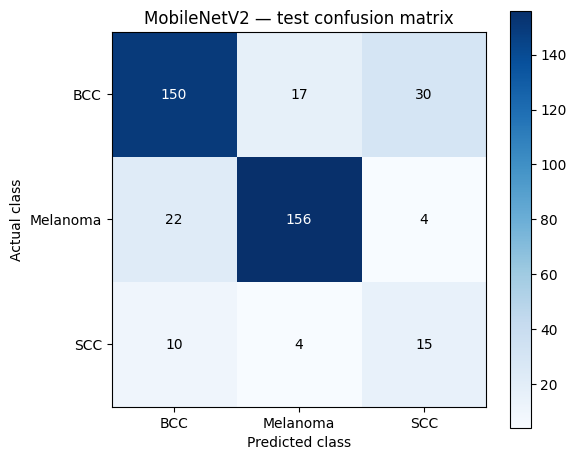

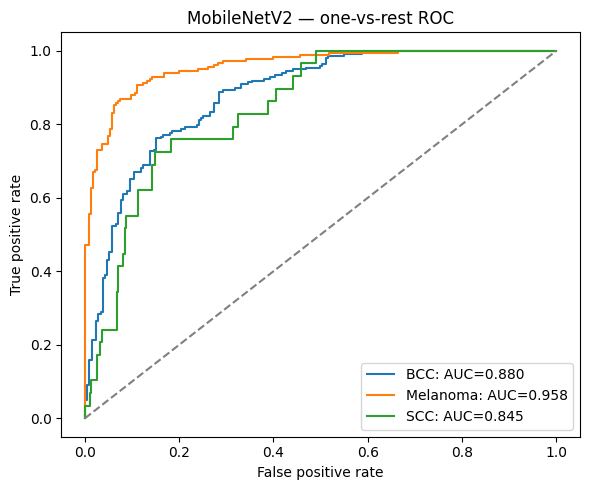


EVALUATING: EfficientNetB0
26/26 ━━━━━━━━━━━━━━━━━━━━ 10s 400ms/step
Saved-model validation reference: passed


,class_label,support,precision,sensitivity_recall,specificity_ovr,f1_score,roc_auc_ovr,true_positive,false_negative,false_positive,true_negative
0,BCC,197,0.8306,0.7716,0.8531,0.8000,0.9036,152,45,31,180
1,Melanoma,182,0.8777,0.9066,0.8982,0.8919,0.9696,165,17,23,203
2,SCC,29,0.3784,0.4828,0.9393,0.4242,0.8874,14,15,23,356


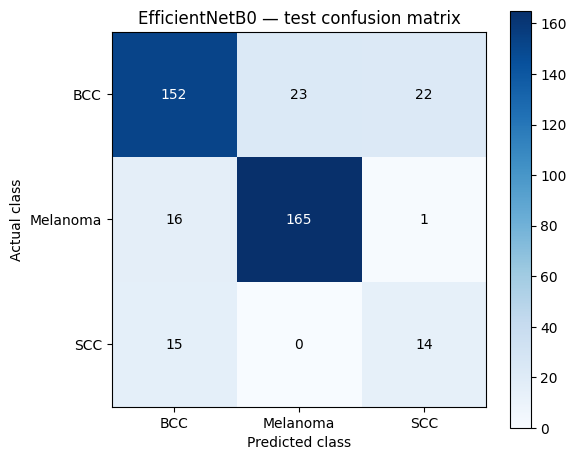

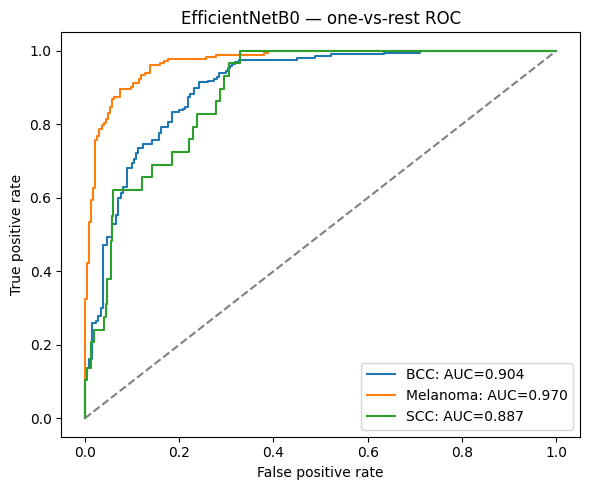


EVALUATING: ResNet50
26/26 ━━━━━━━━━━━━━━━━━━━━ 6s 235ms/step
Saved-model validation reference: passed


,class_label,support,precision,sensitivity_recall,specificity_ovr,f1_score,roc_auc_ovr,true_positive,false_negative,false_positive,true_negative
0,BCC,197,0.8358,0.8528,0.8436,0.8442,0.9258,168,29,33,178
1,Melanoma,182,0.9185,0.9286,0.9336,0.9235,0.9846,169,13,15,211
2,SCC,29,0.3913,0.3103,0.9631,0.3462,0.8848,9,20,14,365


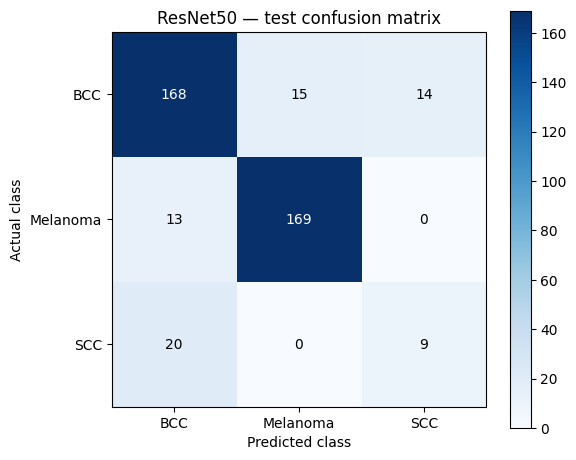

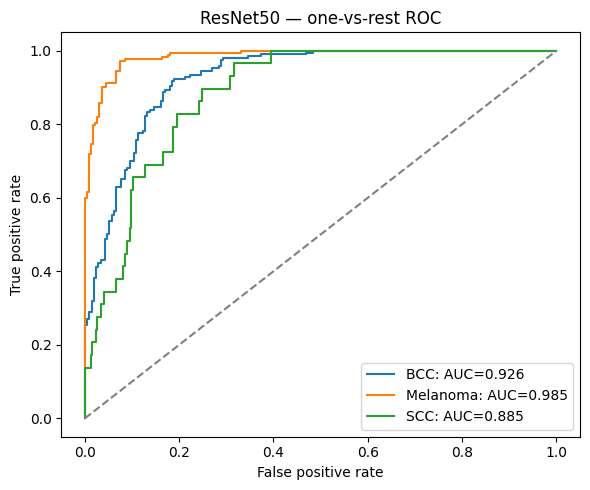

In [8]:
summaries = []
all_predictions = {}
for name in MODEL_NAMES:
    tf.keras.backend.clear_session()
    gc.collect()
    info = metadata[name]
    folder = REPORT_ROOT / name
    folder.mkdir(parents=True, exist_ok=True)
    preprocess = PREPROCESSORS[info['preprocessing']]
    model = tf.keras.models.load_model(MODEL_ROOT / name / 'best.keras', compile=False)

    # Verify saved-model outputs against notebook 5's validation reference.
    reference_frame = pd.read_csv(TRAINING_ROOT / name / 'validation_reference_images.csv')
    with np.load(TRAINING_ROOT / name / 'validation_reference.npz') as archive:
        reference_scores = archive['scores'].copy()
        reference_labels = archive['labels'].copy()
    assert np.array_equal(reference_labels, reference_frame['label_index'].to_numpy())
    reference_images = tf.stack([read_image(str(path)) for path in reference_frame['image_path']])
    current_scores = model.predict(preprocess(reference_images), verbose=0)
    np.testing.assert_allclose(current_scores, reference_scores, rtol=1e-3, atol=1e-4)

    test_ds = RAW_TEST.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
    print('\nEVALUATING:', name)
    probabilities = model.predict(test_ds, verbose=1)
    if probabilities.shape != (len(test_frame), 3) or not np.isfinite(probabilities).all():
        raise ValueError('Invalid model output shape or scores.')
    if (probabilities < 0).any():
        raise ValueError('Negative softmax scores found.')
    np.testing.assert_allclose(probabilities.sum(axis=1), 1.0, atol=1e-5)
    summary, per_class, matrix = compute_metrics(TEST_LABELS, probabilities)
    summary.update({'model_name': name, 'selected_from_validation': name == SELECTED_NAME,
                    'validation_macro_f1': info['validation_macro_f1']})
    summaries.append(summary)
    all_predictions[name] = probabilities
    per_class.to_csv(folder / 'per_class_metrics.csv', index=False)
    write_json(folder / 'test_metrics.json', summary)
    pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(folder / 'confusion_matrix.csv')
    predictions = test_frame.drop(columns=['local_path']).copy()
    predicted = probabilities.argmax(axis=1)
    predictions['predicted_class'] = np.asarray(CLASS_NAMES)[predicted]
    predictions['model_score'] = probabilities.max(axis=1)
    predictions['correct'] = predicted == TEST_LABELS
    for index, class_name in enumerate(CLASS_NAMES):
        predictions[f'score_{class_name}'] = probabilities[:, index]
    predictions.to_csv(folder / 'test_predictions.csv', index=False)
    predictions[~predictions['correct']].to_csv(folder / 'misclassified_images.csv', index=False)

    source_rows = []
    for dataset_name, indices in test_frame.groupby('dataset').groups.items():
        indices = np.asarray(list(indices))
        source_labels = TEST_LABELS[indices]
        source_predictions = predicted[indices]
        present_classes = np.unique(source_labels)
        source_rows.append({
            'dataset': dataset_name, 'image_count': len(indices),
            'represented_classes': ', '.join(CLASS_NAMES[index] for index in present_classes),
            'accuracy': float(accuracy_score(source_labels, source_predictions)),
            'macro_f1_present_classes': float(f1_score(source_labels, source_predictions,
                labels=present_classes, average='macro', zero_division=0)),
        })
    pd.DataFrame(source_rows).to_csv(folder / 'metrics_by_dataset.csv', index=False)
    print('Saved-model validation reference: passed')
    display(per_class.round(4))
    save_figures(name, TEST_LABELS, probabilities, matrix, folder)
    del model, test_ds, reference_images
    gc.collect()

In [9]:
comparison = pd.DataFrame(summaries)
columns = ['model_name', 'selected_from_validation', 'accuracy', 'macro_sensitivity',
           'macro_specificity', 'macro_f1', 'macro_roc_auc_ovr']
comparison.to_csv(REPORT_ROOT / 'test_model_comparison.csv', index=False)
display(comparison[columns].round(4))
selected_result = next(row for row in summaries if row['model_name'] == SELECTED_NAME)
write_json(SELECTED_ROOT / 'test_metrics.json', selected_result)
shutil.copyfile(REPORT_ROOT / SELECTED_NAME / 'per_class_metrics.csv', SELECTED_ROOT / 'per_class_metrics.csv')
write_json(REPORT_ROOT / 'evaluation_manifest.json', {
    'run_id': RUN_ID, 'selected_model': SELECTED_NAME,
    'selection_basis': 'validation macro F1; unchanged after test evaluation',
    'manifest_hashes': manifest_hashes, 'class_names': CLASS_NAMES,
    'tensorflow_version': tf.__version__, 'sklearn_version': sklearn.__version__,
    'evaluated_at_utc': datetime.now(timezone.utc).isoformat(),
    'test_records': len(test_frame),
})
print('MODEL EVALUATION COMPLETE')
print('Deployment candidate remains:', SELECTED_NAME)
print('Selected-model test accuracy:', round(selected_result['accuracy'], 4))
print('Selected-model test macro F1:', round(selected_result['macro_f1'], 4))
print('Proposal accuracy target (>= 0.85):', selected_result['accuracy'] >= 0.85)
print('Proposal macro F1 target (> 0.80):', selected_result['macro_f1'] > 0.80)
print('Reports saved to:', REPORT_ROOT)
print('Selected model package:', SELECTED_ROOT)

,model_name,selected_from_validation,accuracy,macro_sensitivity,macro_specificity,macro_f1,macro_roc_auc_ovr
0,MobileNetV2,False,0.7868,0.7119,0.8886,0.6818,0.8943
1,EfficientNetB0,True,0.8113,0.7203,0.8969,0.7054,0.9202
2,ResNet50,False,0.8480,0.6972,0.9134,0.7046,0.9317


MODEL EVALUATION COMPLETE
Deployment candidate remains: EfficientNetB0
Selected-model test accuracy: 0.8113
Selected-model test macro F1: 0.7054
Proposal accuracy target (>= 0.85): False
Proposal macro F1 target (> 0.80): False
Reports saved to: /content/drive/MyDrive/cnn-skin-cancer-classification/Reports/Evaluation/77751764c605
Selected model package: /content/drive/MyDrive/cnn-skin-cancer-classification/Models/Selected/77751764c605


## Interpretation and limitations

The deployment model was selected using validation macro F1 before test evaluation. Test results are reported for all models, but do not change that selection.

The classifier has no benign/no-cancer class. Model scores are not calibrated clinical probabilities. SCC support is small and SCC occurs only in PAD-UFES-20, creating potential dataset-source confounding. HAM patient-level separation cannot be established because patient identifiers are unavailable. Performance on these datasets does not establish clinical validity or performance on Kenyan patients or darker skin tones.

Record the actual test results and whether the proposal targets were met. Do not claim targets were met if the measured results are lower.